In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [2]:
df = pd.read_csv('/content/Ecommerce_cleaned (1).csv')

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (25000, 29)


,customer_id,session_id,visit_date,device_type,user_type,marketing_channel,product_id,product_category,unit_price,quantity,...,review_text,review_helpful_votes,payment_method,visit_day,visit_month,visit_weekday,visit_season,session_duration_bucket,revenue_normalized,location
0,1803,0,2024-11-28,2,1,2,894,6,651.57,1,...,1,0,1,28,11,3,0,Long,0.000000,209
1,7964,1,2024-09-25,2,0,4,844,2,945.27,4,...,1,0,2,25,9,2,0,Long,0.000000,213
2,6890,2,2024-05-31,1,1,0,865,0,400.44,4,...,1,0,2,31,5,4,1,Short,0.000000,10
3,4949,3,2024-01-30,1,0,2,851,3,1268.54,2,...,10,4,1,30,1,1,3,Very Long,0.305504,46
4,4896,4,2024-02-25,1,1,5,794,3,880.81,3,...,1,0,1,25,2,6,3,Very Short,0.000000,118


In [3]:
print(df['purchased'].value_counts())

print("\nPurchase Percentage:")
print(df['purchased'].value_counts(normalize=True) * 100)

purchased
0    19384
1     5616
Name: count, dtype: int64

Purchase Percentage:
purchased
0    77.536
1    22.464
Name: proportion, dtype: float64


In [4]:
target = 'purchased'

columns_to_drop = [
    'customer_id',
    'session_id',
    'visit_date',
    'purchased',
    'revenue',
    'discount_amount',
    'revenue_normalized',
    'cart_abandoned',
    'payment_method',
    'rating',
    'review_text',
    'review_helpful_votes',
    'added_to_cart'
]

X = df.drop(columns=columns_to_drop)
y = df[target]

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nSelected Features:")
print(X.columns.tolist())

Feature Shape: (25000, 16)
Target Shape: (25000,)

Selected Features:
['device_type', 'user_type', 'marketing_channel', 'product_id', 'product_category', 'unit_price', 'quantity', 'discount_percent', 'pages_viewed', 'time_on_site_sec', 'visit_day', 'visit_month', 'visit_weekday', 'visit_season', 'session_duration_bucket', 'location']


In [5]:
categorical_columns = [
    'device_type',
    'user_type',
    'marketing_channel',
    'product_category',
    'product_id',
    'visit_month',
    'visit_weekday',
    'visit_season',
    'session_duration_bucket',
    'location'
]

categorical_features = [
    col for col in categorical_columns if col in X.columns
]

numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

print("Categorical Features:", categorical_features)
print("\nNumerical Features:", numerical_features)

Categorical Features: ['device_type', 'user_type', 'marketing_channel', 'product_category', 'product_id', 'visit_month', 'visit_weekday', 'visit_season', 'session_duration_bucket', 'location']

Numerical Features: ['unit_price', 'quantity', 'discount_percent', 'pages_viewed', 'time_on_site_sec', 'visit_day']


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True))

Training Data: (20000, 16)
Testing Data: (5000, 16)

Training Target Distribution:
purchased
0    0.77535
1    0.22465
Name: proportion, dtype: float64

Testing Target Distribution:
purchased
0    0.7754
1    0.2246
Name: proportion, dtype: float64


In [7]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [8]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training Shape:", X_train_processed.shape)
print("Testing Shape:", X_test_processed.shape)

Training Shape: (20000, 1176)
Testing Shape: (5000, 1176)


In [9]:
X_train_ann = X_train_processed.astype('float32')
X_test_ann = X_test_processed.astype('float32')

y_train_ann = y_train.to_numpy().astype('float32')
y_test_ann = y_test.to_numpy().astype('float32')

print("ANN Training Shape:", X_train_ann.shape)
print("ANN Testing Shape:", X_test_ann.shape)

print("Data Type:", X_train_ann.dtype)

ANN Training Shape: (20000, 1176)
ANN Testing Shape: (5000, 1176)
Data Type: float32


In [10]:
model = keras.Sequential([
    layers.Input(shape=(X_train_ann.shape[1],)),

    layers.Dense(64, activation='relu'),

    layers.Dense(32, activation='relu'),

    layers.Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        75,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 77,441 (302.50 KB)

 Trainable params: 77,441 (302.50 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("ANN model compiled successfully!")

ANN model compiled successfully!


In [12]:
history = model.fit(
    X_train_ann,
    y_train_ann,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7725 - loss: 0.5385 - val_accuracy: 0.7782 - val_loss: 0.5285
Epoch 2/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.7746 - loss: 0.5152 - val_accuracy: 0.7782 - val_loss: 0.5360
Epoch 3/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.7791 - loss: 0.4816 - val_accuracy: 0.7655 - val_loss: 0.5671
Epoch 4/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8115 - loss: 0.4101 - val_accuracy: 0.7475 - val_loss: 0.6417
Epoch 5/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8717 - loss: 0.3045 - val_accuracy: 0.6762 - val_loss: 0.7819
Epoch 6/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9266 - loss: 0.1946 - val_accuracy: 0.6793 - val_loss: 1.0073
Epoch 7/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9663 - loss: 0.1088 - val_accuracy: 0.6885 - val_loss: 1.2686
Epoch 8/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9881 - loss: 0.0506 - val_accuracy: 0

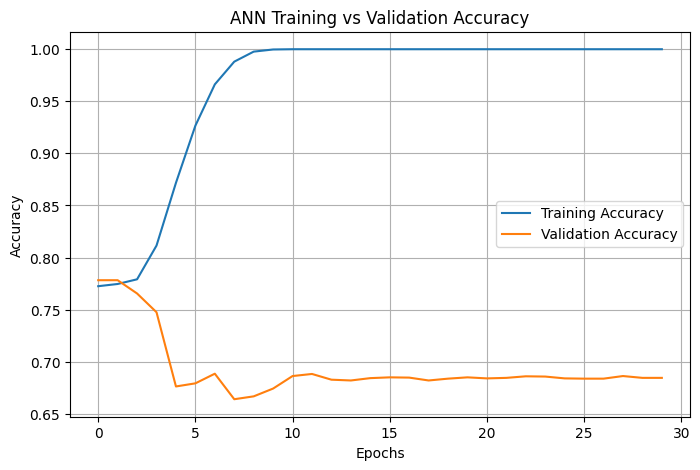

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('ANN Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

In [16]:
test_loss, test_accuracy = model.evaluate(
    X_test_ann,
    y_test_ann,
    verbose=0
)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 4))
print("Test Accuracy Percentage:", round(test_accuracy * 100, 2), "%")

Test Loss: 3.737
Test Accuracy: 0.6856
Test Accuracy Percentage: 68.56 %


In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Predicted probabilities
y_prob_ann = model.predict(X_test_ann).ravel()

# Convert probabilities into binary predictions
y_pred_ann = (y_prob_ann >= 0.50).astype(int)

print("Predictions generated successfully!")
print("Sample probabilities:", y_prob_ann[:10])
print("Sample predictions:", y_pred_ann[:10])

157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
Predictions generated successfully!
Sample probabilities: [2.1938677e-01 9.8885214e-03 8.7984645e-01 9.9999619e-01 4.5218891e-01
 8.0145225e-03 6.2751686e-13 1.0647864e-01 1.1030908e-07 1.4510750e-08]
Sample predictions: [0 0 1 1 0 0 0 0 0 0]


In [18]:
print("ANN MODEL PERFORMANCE")
print("---------------------")

print("Accuracy :", round(accuracy_score(y_test_ann, y_pred_ann), 4))
print("Precision:", round(precision_score(y_test_ann, y_pred_ann, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test_ann, y_pred_ann, zero_division=0), 4))
print("F1 Score :", round(f1_score(y_test_ann, y_pred_ann, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test_ann, y_prob_ann), 4))

ANN MODEL PERFORMANCE
---------------------
Accuracy : 0.6856
Precision: 0.2225
Recall   : 0.1603
F1 Score : 0.1863
ROC-AUC  : 0.5052


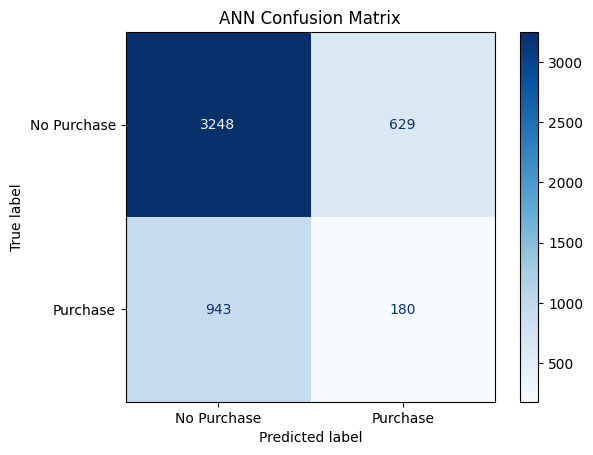

In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test_ann, y_pred_ann)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Purchase', 'Purchase']
)

disp.plot(cmap='Blues', values_format='d')
plt.title('ANN Confusion Matrix')
plt.show()

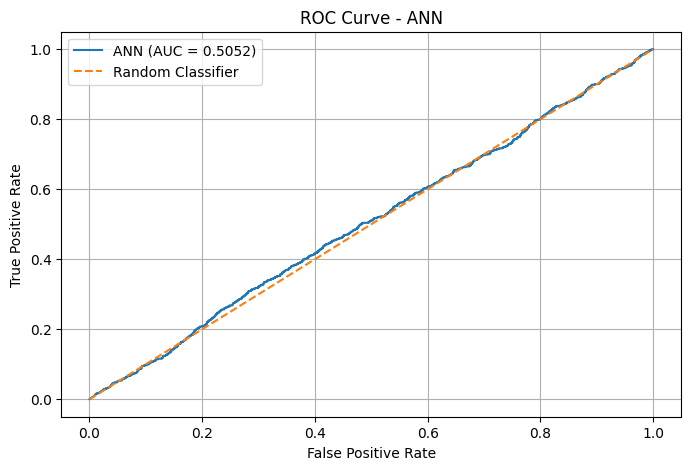

In [20]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_test_ann, y_prob_ann)

auc_score = roc_auc_score(y_test_ann, y_prob_ann)

plt.figure(figsize=(8, 5))

plt.plot(fpr, tpr, label=f'ANN (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - ANN')
plt.legend()
plt.grid(True)
plt.show()

In [21]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test_ann,
    y_pred_ann,
    target_names=['No Purchase', 'Purchase'],
    zero_division=0
))

              precision    recall  f1-score   support

 No Purchase       0.77      0.84      0.81      3877
    Purchase       0.22      0.16      0.19      1123

    accuracy                           0.69      5000
   macro avg       0.50      0.50      0.50      5000
weighted avg       0.65      0.69      0.67      5000



In [22]:
import os
import joblib

os.makedirs('/content/models', exist_ok=True)

# Save ANN model
model.save('/content/models/customer_purchase_ann.keras')

# Save preprocessing pipeline
joblib.dump(
    preprocessor,
    '/content/models/customer_purchase_ann_preprocessor.joblib'
)

print("ANN model and preprocessor saved successfully!")

ANN model and preprocessor saved successfully!
